# Shoulder-based hand landmark normalization — controlled experiment

**Research question:** Does shoulder-centered normalization of MediaPipe hand landmarks improve recognition of four Dutch Sign Language classes (`idle`, `poes`, `slapen`, `vogel`)?

This notebook contains the entire experiment: data inspection, fixed split, normalization, baseline and normalized training, evaluation on an independent new-recording set, and visualizations.

**Important:** New recordings must not have been used to train either model. Training is run only when you execute the training cell.

## 1. Setup
Run this notebook with the same Python environment you use for your project (`gesture-recognition`). Start Jupyter from the **project root** (the folder containing `mp_data` and `modules`).

In [12]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import tensorflow as tf
from modules.model_factory import SimpleModel

# Support launching Jupyter from either project root or main_files/experiments
ROOT = Path.cwd().resolve()
if not (ROOT / "modules").exists():
    for candidate in [ROOT, *ROOT.parents]:
        if (candidate / "modules").exists():
            ROOT = candidate
            break
if not (ROOT / "modules").exists():
    raise FileNotFoundError("Start Jupyter in your project root (the folder containing 'modules').")
sys.path.insert(0, str(ROOT))

ACTIONS = ["idle", "poes", "slapen", "vogel"]
TRAIN_DATA = ROOT / "mp_data"
NEW_TEST_DATA = ROOT / "mp_data_new_test"
OUTPUT = ROOT / "output_models" / "landmark_normalization_experiment"
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 42
EPOCHS = 50
BATCH_SIZE = 8
print("Project root:", ROOT)
print("TensorFlow:", tf.__version__)
print("Model outputs:", OUTPUT)
print("Model outputs:", OUTPUT)

Project root: /Users/youssraakdimi/Documents/GitHub/sign-language-alphabet-recognition
TensorFlow: 2.21.0
Model outputs: /Users/youssraakdimi/Documents/GitHub/sign-language-alphabet-recognition/output_models/landmark_normalization_experiment
Model outputs: /Users/youssraakdimi/Documents/GitHub/sign-language-alphabet-recognition/output_models/landmark_normalization_experiment


## 2. Normalization method
For each frame, subtract the midpoint of pose shoulders (landmarks 11 and 12) from the **x and y** coordinates of both hands. Entirely missing hands (all zeros) remain zero. Pose, face, and hand z-coordinates are unchanged. This is **translation normalization**, not scale normalization.

In [2]:
def normalize_hands(features):
    features = np.asarray(features)
    if features.ndim != 2 or features.shape[1] != 1659:
        raise ValueError(f"Expected (frames, 1659), got {features.shape}")
    normalized = features.copy()
    for frame in normalized:
        pose = frame[126:225].reshape(33, 3)
        left_shoulder, right_shoulder = pose[11], pose[12]
        if (not np.isfinite(left_shoulder).all()
                or not np.isfinite(right_shoulder).all()
                or np.all(left_shoulder == 0)
                or np.all(right_shoulder == 0)):
            continue
        center = (left_shoulder + right_shoulder) / 2
        for start, end in [(0, 63), (63, 126)]:
            hand = frame[start:end].reshape(21, 3)
            if not np.all(hand == 0):
                hand[:, :2] -= center[:2]
    return normalized

## 3. Load recordings
Each sequence folder must contain exactly 30 `.npy` frames, each with 1,659 values. Incomplete folders are skipped and reported.

In [3]:
def load_recordings(data_dir):
    if not data_dir.exists():
        raise FileNotFoundError(f"Missing dataset: {data_dir}")
    sequences, labels, names, skipped = [], [], [], []
    for label, action in enumerate(ACTIONS):
        folder = data_dir / action
        if not folder.exists():
            raise FileNotFoundError(f"Missing class folder: {folder}")
        for recording in sorted(p for p in folder.iterdir() if p.is_dir()):
            frames = sorted(recording.glob("*.npy"))
            if len(frames) != 30:
                skipped.append((str(recording.relative_to(data_dir)), len(frames)))
                continue
            sequence = np.stack([np.load(p) for p in frames]).astype(np.float32)
            if sequence.shape != (30, 1659) or not np.isfinite(sequence).all():
                skipped.append((str(recording.relative_to(data_dir)), "invalid shape/values"))
                continue
            sequences.append(sequence)
            labels.append(label)
            names.append(f"{action}/{recording.name}")
    if not sequences:
        raise ValueError(f"No valid sequences in {data_dir}")
    if skipped:
        print(f"Skipped {len(skipped)} incomplete/invalid sequences in {data_dir.name}")
        print("Examples:", skipped[:5])
    return np.stack(sequences), np.asarray(labels, dtype=np.int64), np.asarray(names)

x_all, y_all, names_all = load_recordings(TRAIN_DATA)
print("Original recordings:", x_all.shape)
print(pd.Series([ACTIONS[y] for y in y_all]).value_counts().sort_index())

Original recordings: (120, 30, 1659)
idle      30
poes      30
slapen    30
vogel     30
Name: count, dtype: int64


## 4. Fixed 80/20 train/test split
The same recording indices and labels are used for both models. No normalization parameters are fitted to the test set: the shoulder reference is computed independently for each frame.

In [4]:
indices = np.arange(len(y_all))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED, stratify=y_all
)
x_train, x_test = x_all[train_idx], x_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
x_train_norm = np.stack([normalize_hands(x) for x in x_train])
x_test_norm = np.stack([normalize_hands(x) for x in x_test])
assert x_train.shape == x_train_norm.shape
assert x_test.shape == x_test_norm.shape
assert np.array_equal(x_test[:, :, 126:], x_test_norm[:, :, 126:])
for start, end in [(0, 63), (63, 126)]:
    assert np.array_equal(
        np.all(x_test[:, :, start:end] == 0, axis=2),
        np.all(x_test_norm[:, :, start:end] == 0, axis=2)
    )
print("Train:", x_train.shape, "Test:", x_test.shape)
print("Modified train values:", np.count_nonzero(x_train != x_train_norm))

Train: (96, 30, 1659) Test: (24, 30, 1659)
Modified train values: 91308


## 5. Train both models
**Run this cell to retrain** both models with the same architecture, seed, epoch count, batch size, and split. Each model is saved in a separate experiment subfolder; Johns existing `output_models/simple_model.h5` is not touched. The `.keras` format is recommended for new Keras models.

Note: A fixed seed improves reproducibility but does not guarantee bit-for-bit identical training across all hardware. Repeat runs with several seeds for stronger evidence.

In [13]:
def train_model(x, y, model_name, seed=SEED):
    tf.keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    model = SimpleModel().create(input_shape=(30, 1659), action_length=len(ACTIONS))
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(x, y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
    path = OUTPUT / f"{model_name}.keras"
    model.save(path)
    print("Saved:", path)
    return model, history

baseline_model, baseline_history = train_model(x_train, y_train, "baseline")
normalized_model, normalized_history = train_model(x_train_norm, y_train, "normalized")

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.2188 - loss: 1.4504
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3021 - loss: 1.4007
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2083 - loss: 1.4045
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3646 - loss: 1.3563
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3542 - loss: 1.3358
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4583 - loss: 1.2272
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3854 - loss: 1.2195
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4896 - loss: 1.1332
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4375 - loss: 1.1348
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4375 - loss: 1.1139
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5625 - loss: 0.9420
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy:

## 6. Plot training history

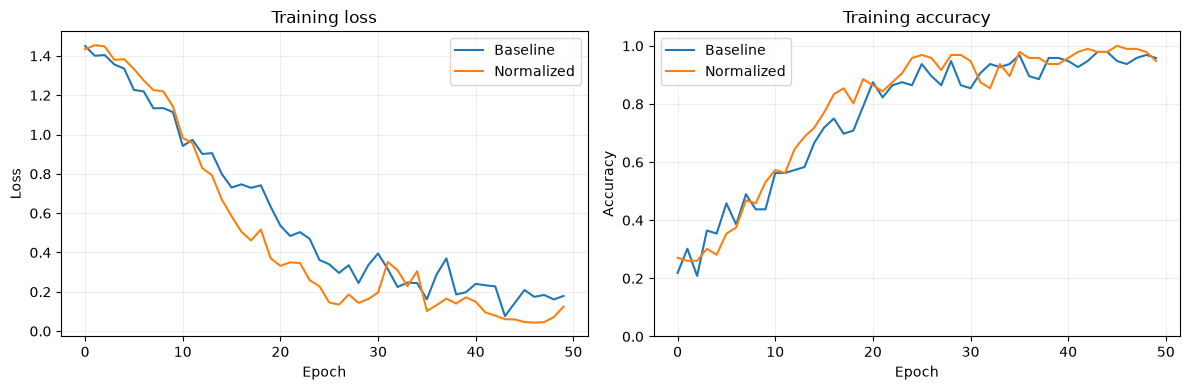

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, history in [("Baseline", baseline_history), ("Normalized", normalized_history)]:
    axes[0].plot(history.history["loss"], label=label)
    axes[1].plot(history.history["accuracy"], label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Evaluate on original held-out recordings

In [15]:
def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)

original_base_pred = predictions(baseline_model, x_test)
original_norm_pred = predictions(normalized_model, x_test_norm)
original_results = {
    "Baseline": accuracy_score(y_test, original_base_pred),
    "Normalized": accuracy_score(y_test, original_norm_pred),
}
print("Original test set (n=%d):" % len(y_test), original_results)

Original test set (n=24): {'Baseline': 1.0, 'Normalized': 1.0}


## 8. Evaluate on **new, independent** recordings
Do not add `mp_data_new_test` to training. Both models are tested on exactly the same recordings; only the normalized model receives normalized features.

In [16]:
x_new, y_new, new_names = load_recordings(NEW_TEST_DATA)
x_new_norm = np.stack([normalize_hands(x) for x in x_new])
new_base_pred = predictions(baseline_model, x_new)
new_norm_pred = predictions(normalized_model, x_new_norm)
new_results = {
    "Baseline": accuracy_score(y_new, new_base_pred),
    "Normalized": accuracy_score(y_new, new_norm_pred),
}
print("New recordings (n=%d):" % len(y_new), new_results)
print("Difference in percentage points:", round(100 * (new_results["Normalized"] - new_results["Baseline"]), 2))

New recordings (n=120): {'Baseline': 0.48333333333333334, 'Normalized': 0.5666666666666667}
Difference in percentage points: 8.33


## 9. Visualize overall and per-sign accuracy

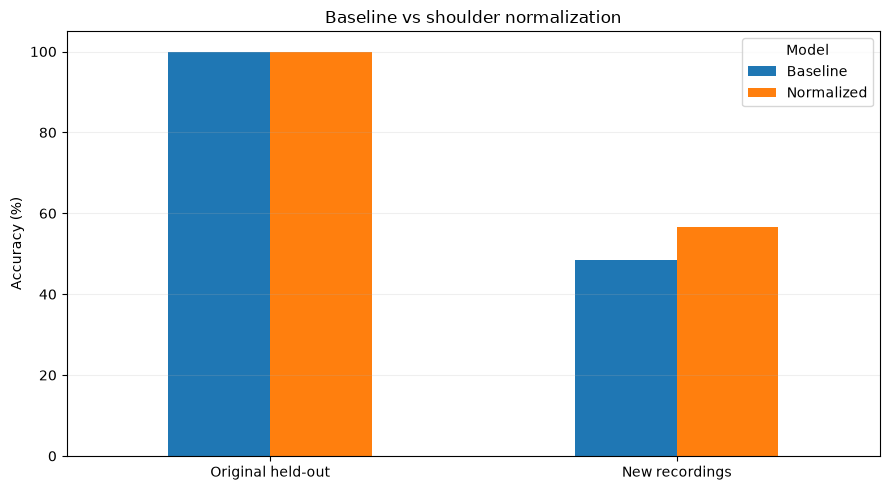

,Baseline,Normalized
Original held-out,100.00,100.00
New recordings,48.33,56.67


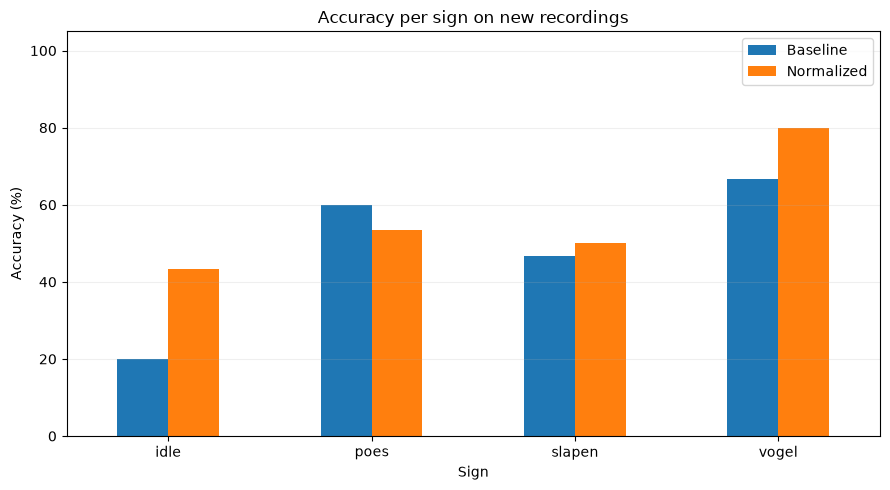

,Recordings,Baseline,Normalized
Sign,,,
idle,30,20.00,43.33
poes,30,60.00,53.33
slapen,30,46.67,50.00
vogel,30,66.67,80.00


In [17]:
overall = pd.DataFrame({
    "Original held-out": original_results,
    "New recordings": new_results,
}).T * 100
ax = overall.plot.bar(figsize=(9, 5), rot=0)
ax.set(ylabel="Accuracy (%)", title="Baseline vs shoulder normalization", ylim=(0, 105))
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
display(overall.round(2))

per_sign = []
for i, action in enumerate(ACTIONS):
    mask = y_new == i
    if mask.any():
        per_sign.append({
            "Sign": action,
            "Recordings": int(mask.sum()),
            "Baseline": 100 * accuracy_score(y_new[mask], new_base_pred[mask]),
            "Normalized": 100 * accuracy_score(y_new[mask], new_norm_pred[mask]),
        })
per_sign_df = pd.DataFrame(per_sign).set_index("Sign")
ax = per_sign_df[["Baseline", "Normalized"]].plot.bar(figsize=(9, 5), rot=0)
ax.set(ylabel="Accuracy (%)", title="Accuracy per sign on new recordings", ylim=(0, 105))
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
display(per_sign_df.round(2))

## 10. Inspect individual predictions and save results
This table shows exactly which new recordings changed from incorrect to correct (or vice versa). It is often more informative than the overall accuracy alone.

In [18]:
details = pd.DataFrame({
    "recording": new_names,
    "actual": [ACTIONS[i] for i in y_new],
    "baseline_prediction": [ACTIONS[i] for i in new_base_pred],
    "normalized_prediction": [ACTIONS[i] for i in new_norm_pred],
    "baseline_correct": new_base_pred == y_new,
    "normalized_correct": new_norm_pred == y_new,
})
details["normalization_effect"] = np.select(
    [~details.baseline_correct & details.normalized_correct,
     details.baseline_correct & ~details.normalized_correct],
    ["Improved", "Worsened"], default="Same outcome"
)
display(details)
print(details["normalization_effect"].value_counts())
details.to_csv(OUTPUT / "new_recording_predictions.csv", index=False)
overall.to_csv(OUTPUT / "accuracy_summary_percent.csv")
per_sign_df.to_csv(OUTPUT / "accuracy_per_sign_percent.csv")
print("CSV results saved in:", OUTPUT)

,recording,actual,baseline_prediction,normalized_prediction,baseline_correct,normalized_correct,normalization_effect
0,idle/000,idle,idle,idle,True,True,Same outcome
1,idle/001,idle,slapen,idle,False,True,Improved
2,idle/002,idle,idle,idle,True,True,Same outcome
3,idle/003,idle,idle,idle,True,True,Same outcome
4,idle/004,idle,idle,idle,True,True,Same outcome
...,...,...,...,...,...,...,...
115,vogel/025,vogel,vogel,vogel,True,True,Same outcome
116,vogel/026,vogel,vogel,vogel,True,True,Same outcome
117,vogel/027,vogel,vogel,vogel,True,True,Same outcome
118,vogel/028,vogel,vogel,vogel,True,True,Same outcome


normalization_effect
Same outcome    86
Improved        22
Worsened        12
Name: count, dtype: int64
CSV results saved in: /Users/youssraakdimi/Documents/GitHub/sign-language-alphabet-recognition/output_models/landmark_normalization_experiment
